# Multimodal Heart Disease Prediction — Research Pipeline

**Investigational & Research Prototype Only.** Not for clinical diagnosis or triage.

This notebook demonstrates the end-to-end multimodal deep learning pipeline combining:
1. **12-Lead ECG Waveforms** (1D Multi-Scale CNN + BiLSTM + Attention Pooling)
2. **Structured Clinical Features** (Missingness-aware MLP)
3. **Dynamic Cross-Modal Fusion** (Gated Fusion & Cross-Attention)
4. **Patient-Grouped Leakage-Free Splitting**
5. **Explainability & Attribution Analysis** (Integrated Gradients & Tabular Attributions)
6. **Versioned Model Packaging**

In [1]:
import os, sys, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
# Ensure project root is in path
sys.path.append(os.path.abspath(".."))
from src.data.csv_loader import DEFAULT_CLINICAL_FEATURES, load_cohort_from_csv
from src.data.ecg_processor import ECGProcessor
from src.data.clinical_processor import ClinicalProcessor
from src.data.dataset import MultimodalDataset, patient_level_split, create_dataloaders
from src.models.multimodal_classifier import MultimodalClassifier
from src.models.baselines import ECGOnlyClassifier, ClinicalOnlyClassifier
from src.models.trainer import MultimodalTrainer, compute_binary_metrics, find_optimal_threshold
from src.models.explainability import compute_ecg_saliency, compute_clinical_attributions
from src.models.artifact import ModelArtifactManager
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Computation Device:", DEVICE)
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


Computation Device: cpu


## 1. Cohort Ingestion & Signal Synthesis

We load the cohort directly from the CSV dataset (), combining clinical features and 12-lead ECG waveforms.


In [2]:
df_clinical, raw_ecgs = load_cohort_from_csv("../data/heart_disease_multimodal.csv")
print(f"Cohort Size: {len(df_clinical)} records from {df_clinical['patient_id'].nunique()} patients")
print("ECG Tensor Shape:", raw_ecgs.shape) # [N, 12, 2500]
df_clinical.head()

Cohort Size: 449 records from 300 patients
ECG Tensor Shape: (449, 12, 2500)


,record_id,patient_id,age,sex,resting_bp,cholesterol,fasting_bs,resting_ecg,max_hr,exercise_angina,st_depression,st_slope,num_major_vessels,thal,target
0,REC_0001_1,PAT_0001,60,1.0,133.092075,245.774733,0.0,0.0,135.848491,0.0,2.659896,0.0,0.0,0.0,1
1,REC_0001_2,PAT_0001,60,1.0,133.092075,245.774733,0.0,0.0,135.848491,0.0,2.659896,0.0,0.0,0.0,1
2,REC_0002_1,PAT_0002,49,1.0,NaN,164.582856,0.0,0.0,175.077041,0.0,1.187321,2.0,0.0,0.0,0
3,REC_0003_1,PAT_0003,47,0.0,102.061292,203.721118,0.0,2.0,139.606830,0.0,1.649150,0.0,0.0,1.0,0
4,REC_0004_1,PAT_0004,63,1.0,107.477887,181.690199,0.0,0.0,130.770417,1.0,0.888295,1.0,0.0,2.0,1


/tmp/ipykernel_5297/1913309897.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Healthy (0)", "Disease (1)"])


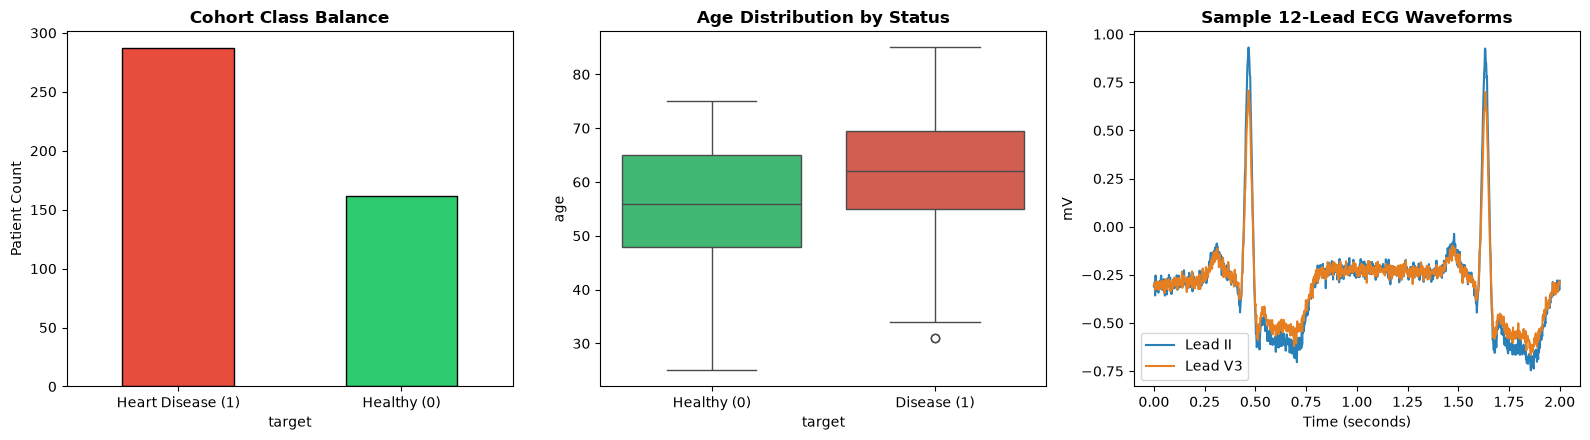

In [3]:
# Visualizing Cohort Distributions and 12-Lead ECG Signals
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
df_clinical["target"].value_counts().plot(kind="bar", color=["#e74c3c", "#2ecc71"], ax=axes[0], edgecolor="black")
axes[0].set_title("Cohort Class Balance", fontweight="bold")
axes[0].set_xticklabels(["Heart Disease (1)", "Healthy (0)"], rotation=0)
axes[0].set_ylabel("Patient Count")

sns.boxplot(data=df_clinical, x="target", y="age", palette=["#2ecc71", "#e74c3c"], ax=axes[1], hue="target", legend=False)
axes[1].set_xticklabels(["Healthy (0)", "Disease (1)"])
axes[1].set_title("Age Distribution by Status", fontweight="bold")

t = np.linspace(0, 2.0, 1000)
axes[2].plot(t, raw_ecgs[0, 1, :1000], label="Lead II", color="#2980b9")
axes[2].plot(t, raw_ecgs[0, 8, :1000], label="Lead V3", color="#e67e22")
axes[2].set_title("Sample 12-Lead ECG Waveforms", fontweight="bold")
axes[2].set_xlabel("Time (seconds)")
axes[2].set_ylabel("mV")
axes[2].legend()
plt.tight_layout()
plt.show()


## 2. Patient-Level Leakage-Free Splitting

Crucial clinical ML principle: **Never split serial records or beats from the same patient across train and test!**
We use `GroupShuffleSplit` on `patient_id` to ensure zero patient leakage.

In [4]:
train_idx, val_idx, test_idx = patient_level_split(
    df_clinical,
    patient_col="patient_id",
    target_col="target",
    val_size=0.15,
    test_size=0.15,
    seed=SEED
)
print(f"Partition Counts -> Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

Partition Counts -> Train: 309 | Val: 70 | Test: 70


## 3. Preprocessing: Fit on Training Split Only

- Butterworth bandpass filtering (0.5 Hz – 45.0 Hz) and 50 Hz notch filtering for ECG
- Median imputation and z-score scaling for clinical variables, fitted exclusively on training data

In [5]:
ecg_proc = ECGProcessor(target_fs=500.0, nominal_samples=2500)
proc_ecgs = np.zeros_like(raw_ecgs)
for i in range(len(raw_ecgs)):
    proc_ecgs[i] = ecg_proc.process(raw_ecgs[i], orig_fs=500.0)

feature_cols = [c for c in DEFAULT_CLINICAL_FEATURES if c in df_clinical.columns]
clin_proc = ClinicalProcessor(feature_names=feature_cols)
clin_proc.fit(df_clinical.iloc[train_idx][feature_cols])

X_train_c = clin_proc.transform(df_clinical.iloc[train_idx][feature_cols])
X_val_c = clin_proc.transform(df_clinical.iloc[val_idx][feature_cols])
X_test_c = clin_proc.transform(df_clinical.iloc[test_idx][feature_cols])

y_train = df_clinical.iloc[train_idx]["target"].to_numpy()
y_val = df_clinical.iloc[val_idx]["target"].to_numpy()
y_test = df_clinical.iloc[test_idx]["target"].to_numpy()

train_ds = MultimodalDataset(proc_ecgs[train_idx], X_train_c, y_train)
val_ds = MultimodalDataset(proc_ecgs[val_idx], X_val_c, y_val)
test_ds = MultimodalDataset(proc_ecgs[test_idx], X_test_c, y_test)

loaders = create_dataloaders(train_ds, val_ds, test_ds, batch_size=32)

/home/adarsh/Documents/Heart Disease Prediction/src/data/dataset.py:33: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  self.targets = torch.as_tensor(targets, dtype=torch.float32)


## 4. Train Multimodal Model (Gated Fusion)

In [6]:
model = MultimodalClassifier(
    in_leads=12,
    n_clinical_features=len(feature_cols),
    embedding_dim=128,
    fusion_type="gated"
)
trainer = MultimodalTrainer(model, patience=7)
results = trainer.fit(loaders["train"], loaders["val"], epochs=15, verbose=True)

Epoch 01/15 | Train Loss: 0.6720 | Val Loss: 0.5671 | Val AUROC: 0.8390 | Val F1: 0.8506


Epoch 05/15 | Train Loss: 0.3782 | Val Loss: 0.3170 | Val AUROC: 0.8992 | Val F1: 0.8989


Epoch 10/15 | Train Loss: 0.0672 | Val Loss: 0.1451 | Val AUROC: 0.9972 | Val F1: 0.9670


Epoch 15/15 | Train Loss: 0.0326 | Val Loss: 0.0273 | Val AUROC: 1.0000 | Val F1: 1.0000


## 5. Locked Test Evaluation & Metrics

In [7]:
val_loss, y_val_true, y_val_probs = trainer.evaluate(loaders["val"])
opt_thresh = find_optimal_threshold(y_val_true, y_val_probs)
print(f"Tuned Decision Threshold: {opt_thresh:.3f}")

test_loss, y_test_true, y_test_probs = trainer.evaluate(loaders["test"])
test_metrics = compute_binary_metrics(y_test_true, y_test_probs, threshold=opt_thresh)
for k, v in test_metrics.items():
    print(f"{k:<20}: {v}")

Tuned Decision Threshold: 0.520


auroc               : 0.999
auprc               : 0.9996
accuracy            : 0.9857
f1                  : 0.9901
sensitivity         : 1.0
specificity         : 0.95
precision           : 0.9804
npv                 : 1.0
brier_score         : 0.017
threshold           : 0.52
confusion_matrix    : {'tp': 50, 'fp': 1, 'tn': 19, 'fn': 0}


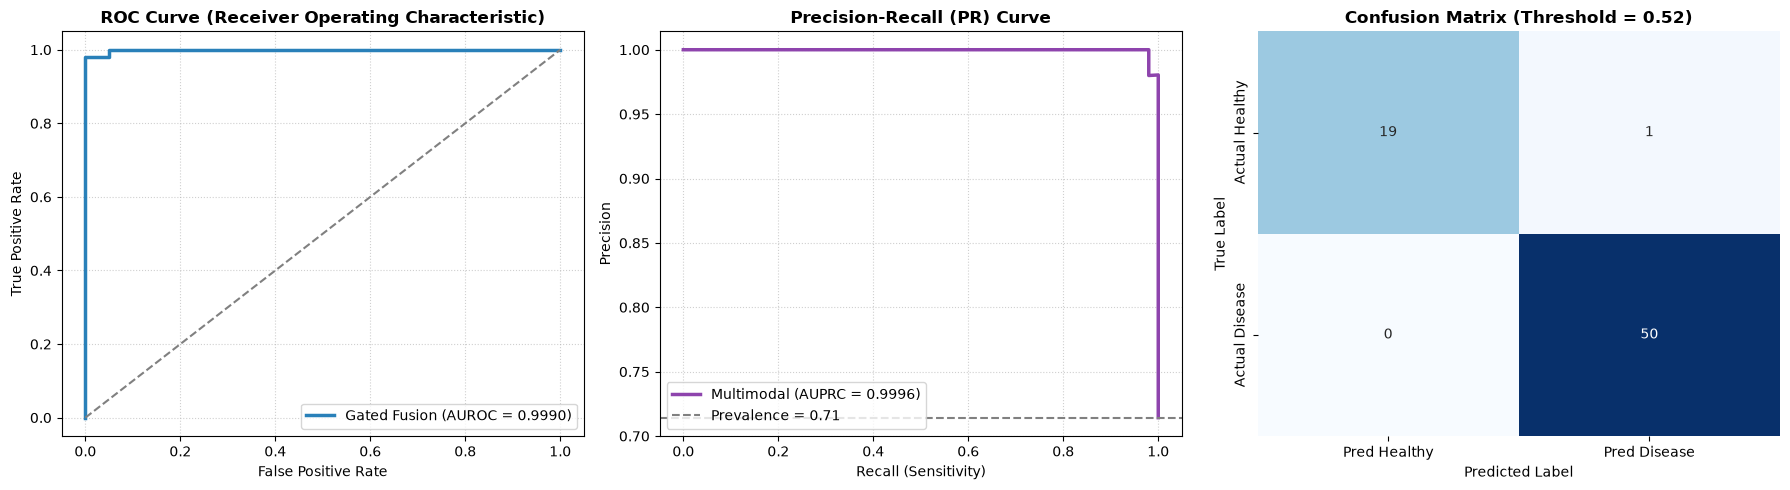

In [8]:
# Diagnostic Curves: ROC Curve, Precision-Recall Curve, and Confusion Matrix
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score, confusion_matrix

fpr, tpr, _ = roc_curve(y_test_true, y_test_probs)
roc_auc = auc(fpr, tpr)
prec, rec, _ = precision_recall_curve(y_test_true, y_test_probs)
pr_auc = average_precision_score(y_test_true, y_test_probs)
cm = confusion_matrix(y_test_true, (y_test_probs >= opt_thresh).astype(int))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC Curve
axes[0].plot(fpr, tpr, color="#2980b9", lw=2.5, label=f"Gated Fusion (AUROC = {roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[0].set_title("ROC Curve (Receiver Operating Characteristic)", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle=":", alpha=0.6)

# PR Curve
axes[1].plot(rec, prec, color="#8e44ad", lw=2.5, label=f"Multimodal (AUPRC = {pr_auc:.4f})")
axes[1].axhline(np.mean(y_test_true), color="gray", linestyle="--", label=f"Prevalence = {np.mean(y_test_true):.2f}")
axes[1].set_title("Precision-Recall (PR) Curve", fontweight="bold")
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="lower left")
axes[1].grid(True, linestyle=":", alpha=0.6)

# Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["Pred Healthy", "Pred Disease"], yticklabels=["Actual Healthy", "Actual Disease"])
axes[2].set_title(f"Confusion Matrix (Threshold = {opt_thresh:.2f})", fontweight="bold")
axes[2].set_ylabel("True Label")
axes[2].set_xlabel("Predicted Label")

plt.tight_layout()
plt.show()


## 6. Explainability: ECG Saliency & Clinical Attributions

In [9]:
sample_ecg = torch.from_numpy(proc_ecgs[test_idx[0]]).float()
sample_clin = torch.from_numpy(X_test_c[0]).float()

saliency = compute_ecg_saliency(model, sample_ecg, sample_clin, steps=10)
print("Top Saliency Leads:")
for lead in saliency["lead_ranking"][:3]:
    print(f"  - {lead['lead']}: weight={lead['weight']:.4f}")

attributions = compute_clinical_attributions(model, sample_ecg, sample_clin, feature_cols)
print("\nTop Clinical Attributions:")
for attr in attributions[:4]:
    print(f"  - {attr['feature']}: score={attr['attribution_score']:.4f} ({attr['direction']})")

Top Saliency Leads:
  - V4: weight=0.1114
  - V1: weight=0.1019
  - V6: weight=0.1002

Top Clinical Attributions:
  - age: score=0.2494 (increases_risk)
  - st_slope: score=0.1650 (increases_risk)
  - exercise_angina: score=0.1554 (increases_risk)
  - fasting_bs: score=0.0942 (decreases_risk)


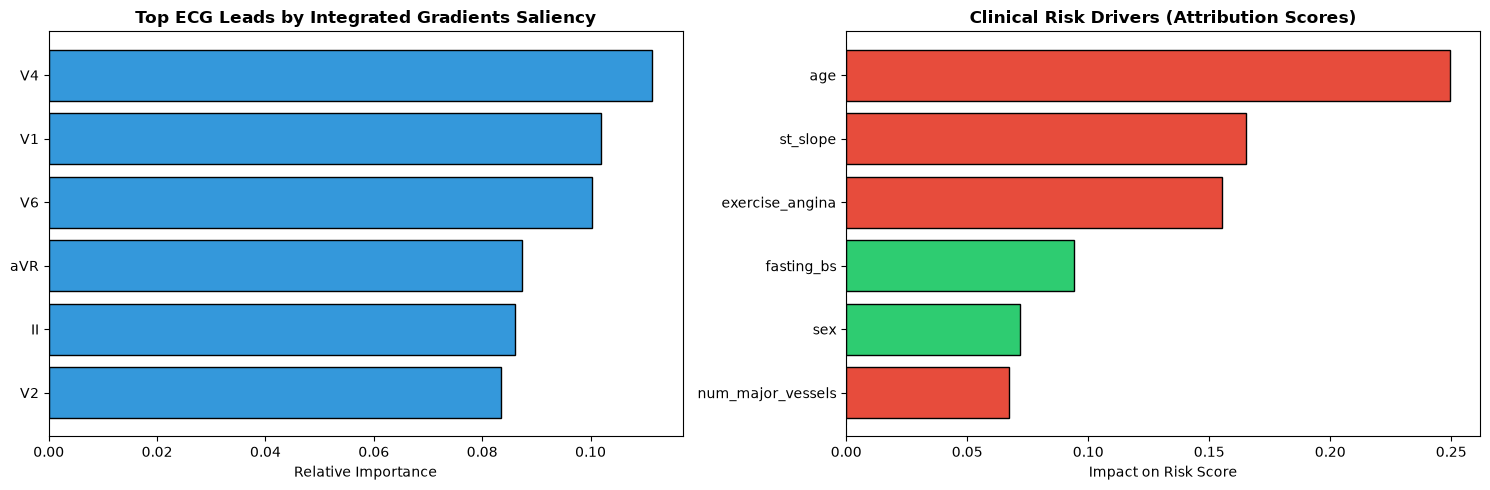

In [10]:
# Visualizing ECG Saliency Leads & Top Clinical Feature Attributions (Vertical Charts)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# 1. ECG Lead Saliency (Vertical graph with multiple colors)
lead_items = saliency["lead_ranking"][:6]
leads = [l["lead"] for l in lead_items]
weights = [l["weight"] for l in lead_items]
lead_colors = ["#0284c7", "#38bdf8", "#818cf8", "#c084fc", "#f472b6", "#10b981"]

bars1 = ax1.bar(leads, weights, color=lead_colors[:len(leads)], edgecolor="black", linewidth=1.0, width=0.55)
ax1.set_title("Top ECG Leads by Integrated Gradients Saliency", fontweight="bold", fontsize=12, pad=10)
ax1.set_ylabel("Relative Importance", fontweight="bold")
ax1.set_xlabel("ECG Lead", fontweight="bold")
ax1.set_xticks(range(len(leads)))
ax1.set_xticklabels(leads, fontweight="bold", fontsize=10)
ax1.grid(True, axis="y", linestyle="--", alpha=0.5)
if weights:
    ax1.set_ylim([0, max(weights) * 1.18])
for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points",
                 ha="center", va="bottom", fontweight="bold", fontsize=9.5)

# 2. Clinical Feature Attributions (Shifted to vertical graph)
top_attrs = sorted(attributions, key=lambda x: abs(x["attribution_score"]), reverse=True)[:6]
f_names = [a["feature"] for a in top_attrs]
scores = [a["attribution_score"] for a in top_attrs]
colors = ["#e74c3c" if a["direction"] == "increases_risk" else "#2ecc71" for a in top_attrs]

bars2 = ax2.bar(f_names, scores, color=colors, edgecolor="black", linewidth=1.0, width=0.55)
ax2.set_title("Clinical Risk Drivers (Attribution Scores)", fontweight="bold", fontsize=12, pad=10)
ax2.set_ylabel("Impact on Risk Score", fontweight="bold")
ax2.set_xlabel("Clinical Feature", fontweight="bold")
ax2.axhline(0, color="gray", linestyle="--", linewidth=1.0)
ax2.set_xticks(range(len(f_names)))
ax2.set_xticklabels(f_names, rotation=30, ha="right", fontweight="bold", fontsize=9.5)
ax2.grid(True, axis="y", linestyle="--", alpha=0.5)
for bar in bars2:
    h = bar.get_height()
    va = "bottom" if h >= 0 else "top"
    offset = (0, 4) if h >= 0 else (0, -12)
    ax2.annotate(f"{h:+.3f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=offset, textcoords="offset points",
                 ha="center", va=va, fontweight="bold", fontsize=9)

handles = [plt.Line2D([0], [0], color="#e74c3c", lw=4, label="Increases Risk"),
           plt.Line2D([0], [0], color="#2ecc71", lw=4, label="Decreases Risk")]
ax2.legend(handles=handles, loc="upper right", frameon=True)

plt.tight_layout()
plt.show()


## 7. Model Artifact Packaging & Integrity Hash

In [11]:
artifact_path = "../artifacts/best_multimodal_model.pt"
sha256 = ModelArtifactManager.save_artifact(
    model=model,
    clinical_processor=clin_proc,
    save_path=artifact_path,
    threshold=opt_thresh,
    version="v1.0.0-multimodal-gated",
    metrics=test_metrics
)
print(f"Model artifact successfully exported to {artifact_path}")
print(f"SHA-256 Checksum: {sha256}")

Model artifact successfully exported to ../artifacts/best_multimodal_model.pt
SHA-256 Checksum: 9589a353ef7571030ed4900fe651282d0820158a459708075eede92e043b8061
